### Visualization

In [2]:
library(ggplot2)
library(ggpubr)
library(data.table)
library(dplyr)

In [3]:
qqplot_unequal_len <- function(dat.group, method_col = 'method', pval_col = 'pval', size=5, color_thresh = '567', legend_show=TRUE, title=NULL, xlim=NULL, comp.labels=NULL,max=40, strong=NULL, mark=T){
    
  if(color_thresh == '567'){
      color.map <- c("5e-5" = "#F8766D", 
                     "5e-05" = "#F8766D", 
                     "5e-6" = "#00BA38", 
                     "5e-06" = "#00BA38", 
                     "5e-7" = "#619CFF",
                     "5e-07" = "#619CFF")
  }else if(color_thresh == '789'){
     color.map <- c("5e-7" = "#F8766D", 
                     "5e-07" = "#F8766D", 
                     "5e-8" = "#00BA38", 
                     "5e-08" = "#00BA38", 
                     "5e-9" = "#619CFF",
                    "5e-09" = "#619CFF")
  }else if(color_thresh == '345'){
     color.map <- c("1e-3" = "#F8766D", 
                     "1e-03" = "#F8766D", 
                     "0.001" = "#F8766D", 
                     "1e-4" = "#00BA38", 
                     "1e-04" = "#00BA38", 
                     "1e-5" = "#619CFF",
                     "1e-05" = "#619CFF")
  }
    
  ci = 0.95
  #dat.group = na.omit(dat.group[, c(comp1, comp2,comp3, comp4, comp5, comp6, comp7)])
  #n  <- nrow(dat.group)
  #cat("n=", n, "\n")
    
  dat.group[[method_col]] = as.character(dat.group[[method_col]])
  method_list = unique(dat.group[[method_col]])
    
  df = NULL

  for(i in 1:length(method_list)){
      num_i = sum(dat.group[[method_col]]==method_list[i])
      df = rbind(df, data.frame(pval = sort(dat.group[dat.group[[method_col]]==method_list[i]][[pval_col]]),
                                Method = rep(method_list[i], num_i),
                                num = num_i,
                                expected = -log10(ppoints(num_i))
                               )
                )
  }
    
  max_len = max(df$num)
    
  df$pval[-log10(df$pval)>=max] = 10^(-1*max)
  df <- data.frame(Method = df$Method,
                   observed = -log10(df$pval),
                   expected = df$expected
                   )
    
  ci_df = data.frame(expected = -log10(ppoints(max_len)),
                     clower = -log10(qbeta(p = (1 - ci) / 2, shape1 = 1:max_len, shape2 = (max_len):1)),
                     cupper = -log10(qbeta(p = (1 + ci) / 2, shape1 = 1:max_len, shape2 = (max_len):1))
                     )
  
  log10Pe <- expression(paste("Expected -log"[10], "(",plain(p), ")"))
  log10Po <- expression(paste("Observed -log"[10], "(",plain(p), ")"))
  
  
  df$Method = factor(df$Method)
    
  if(is.null(xlim)){
      xlim = max(df$expected)
  }
  
  plot = ggplot(df, aes(x=expected, y=observed)) +
    geom_point(data = df,
               aes(x=expected, y=observed,color=Method),size=size,alpha=0.95) +
    # geom_point(data = subset(df, observed >= -log10(0.05/26/5)),
    #            aes(x=expected, y=observed,color=Method), size = 3, shape = 16) +
    geom_abline(intercept = 0, slope = 1, alpha = 0.5, size=1.4) +
    geom_line(data=ci_df, aes(expected, cupper), linetype = 2, color="#999999", size=1.4) +
    geom_line(data=ci_df, aes(expected, clower), linetype = 2, color="#999999", size=1.4) +
    labs(title = title,
    ) +
    xlab(log10Pe) +
    ylab(log10Po) +
    ylim(0, max)+
    xlim(0, xlim)+
    theme_pubr() +
    theme(plot.title = element_text(                
                size = 35,
                #face = "bold",
                hjust = 0.5,
                vjust = 1
          ),
          legend.position = if (legend_show) c(1, 0.025) else "none",
          legend.justification = if (legend_show) c(0.95, 0) else NULL,
          legend.text = element_text(hjust = 0, size=29),
          #legend.title = element_text(hjust = 0, size=24),
          legend.title = element_blank(),
          axis.title = element_text(size = 28, color = "black"),
          axis.text  = element_text(size = 28,color = "black"),
          ) +
    scale_color_manual(values = color.map)
    
  if(!is.null(strong)) plot= plot + geom_point(data=df[which(df$Method==strong),],
                                               aes(color=Method,color=Method, shape=Method,size=Method))
  
  return(plot)
}

In [ ]:
setwd('./nc')

In [5]:
base_dir <- getwd()

In [14]:
dir.create(paste0(base_dir, "/plots"), recursive = TRUE, showWarnings = FALSE)

### XMR

Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”


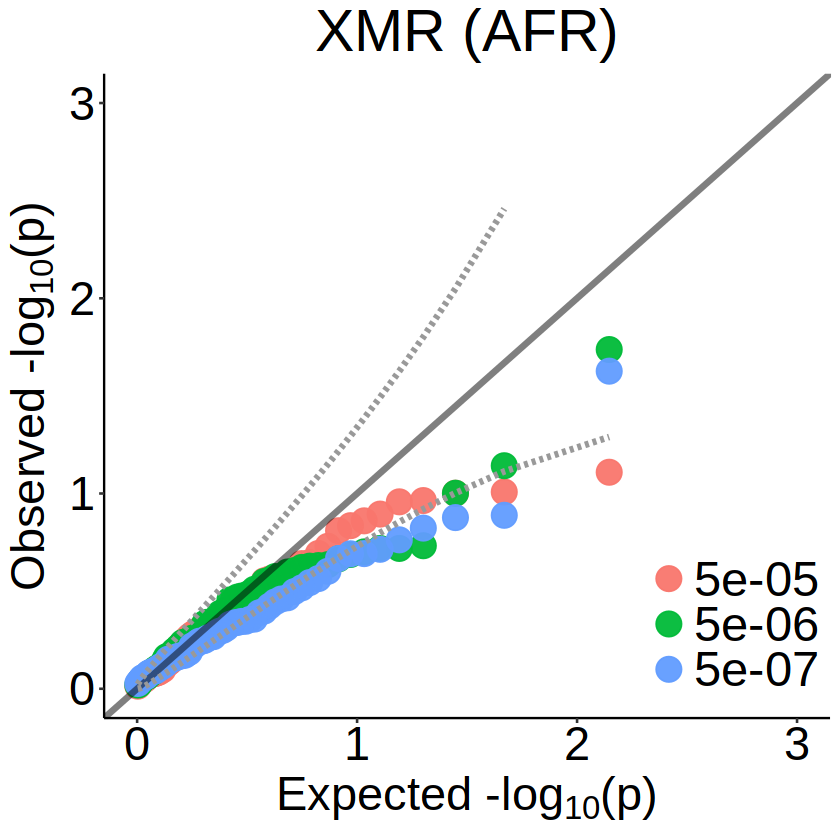

In [23]:
res_xmr_AFR = fread("./AFR_results/XMR.MRres")
res_xmr_AFR = as.data.frame(res_xmr_AFR)
res_xmr_AFR = res_xmr_AFR[as.numeric(res_xmr_AFR$nIV) > 3, ]

res_xmr_AFR$beta.pvalue = as.numeric(res_xmr_AFR$beta.pvalue)
qqplot_unequal_len(as.data.table(distinct(res_xmr_AFR)), method_col = 'Threshold', pval_col = 'beta.pvalue', 
                   title = "XMR (AFR)", max=3, xlim=3,  size=6.5)

ggsave(paste0(base_dir, "/plots/XMR_AFR.png"), width = 7, height = 6, bg = 'white')

Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”


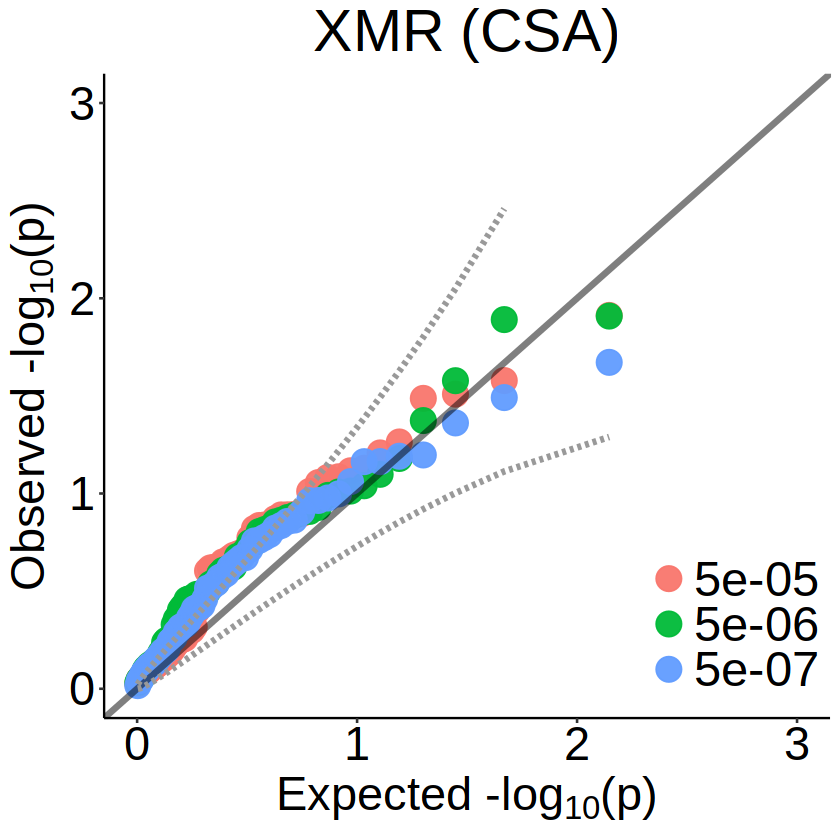

In [24]:
res_xmr_CSA = fread("./CSA_results/XMR.MRres")
res_xmr_CSA = as.data.frame(res_xmr_CSA)
res_xmr_CSA = res_xmr_CSA[as.numeric(res_xmr_CSA$nIV) > 3, ]

res_xmr_CSA$beta.pvalue = as.numeric(res_xmr_CSA$beta.pvalue)
qqplot_unequal_len(as.data.table(distinct(res_xmr_CSA)), method_col = 'Threshold', pval_col = 'beta.pvalue', 
                   title = "XMR (CSA)", max=3, xlim=3,  size=6.5)

ggsave(paste0(base_dir, "/plots/XMR_CSA.png"), width = 7, height = 6, bg = 'white')

### MRAPSS

Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”


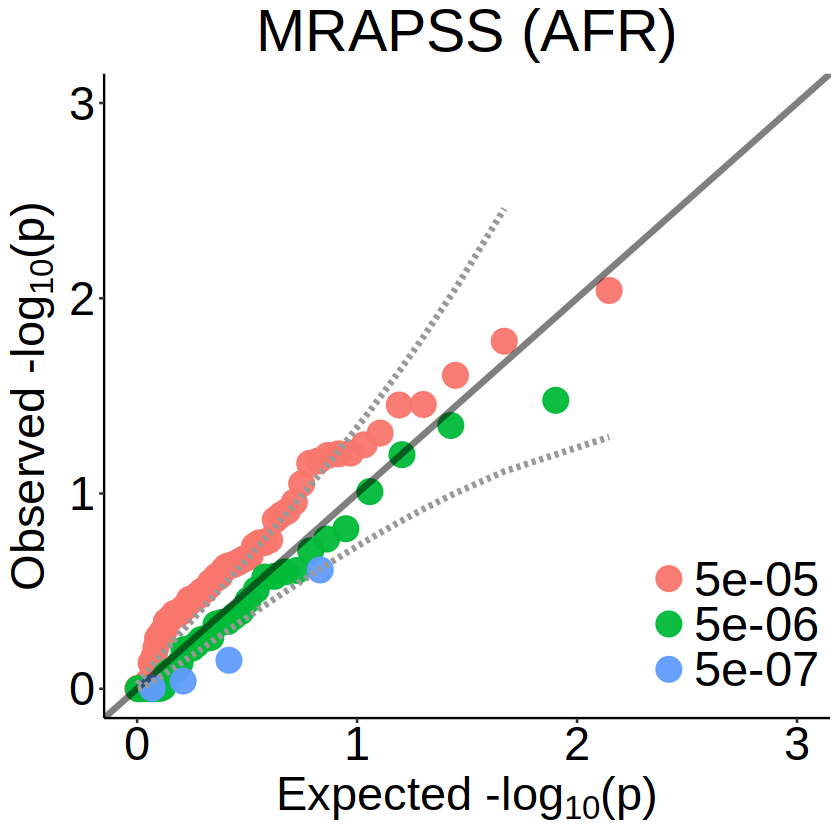

In [33]:
res_mrapss_AFR = fread("./AFR_results/MRAPSS.MRres")
res_mrapss_AFR = as.data.frame(res_mrapss_AFR)
colnames(res_mrapss_AFR) = c('exposure','outcome','beta','beta.se','beta.pvalue','tau.sq','nIV','pi0','IVsignal.sum','Threshold')
res_mrapss_AFR = res_mrapss_AFR[as.numeric(res_mrapss_AFR$nIV) > 3, ]

res_mrapss_AFR$beta.pvalue = as.numeric(res_mrapss_AFR$beta.pvalue)
qqplot_unequal_len(as.data.table(distinct(res_mrapss_AFR)), method_col = 'Threshold', pval_col = 'beta.pvalue', 
                   title = "MRAPSS (AFR)", max=3, xlim=3,  size=6.5)

ggsave(paste0(base_dir, "/plots/MRAPSS_AFR.png"), width = 7, height = 6, bg = 'white')

Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”


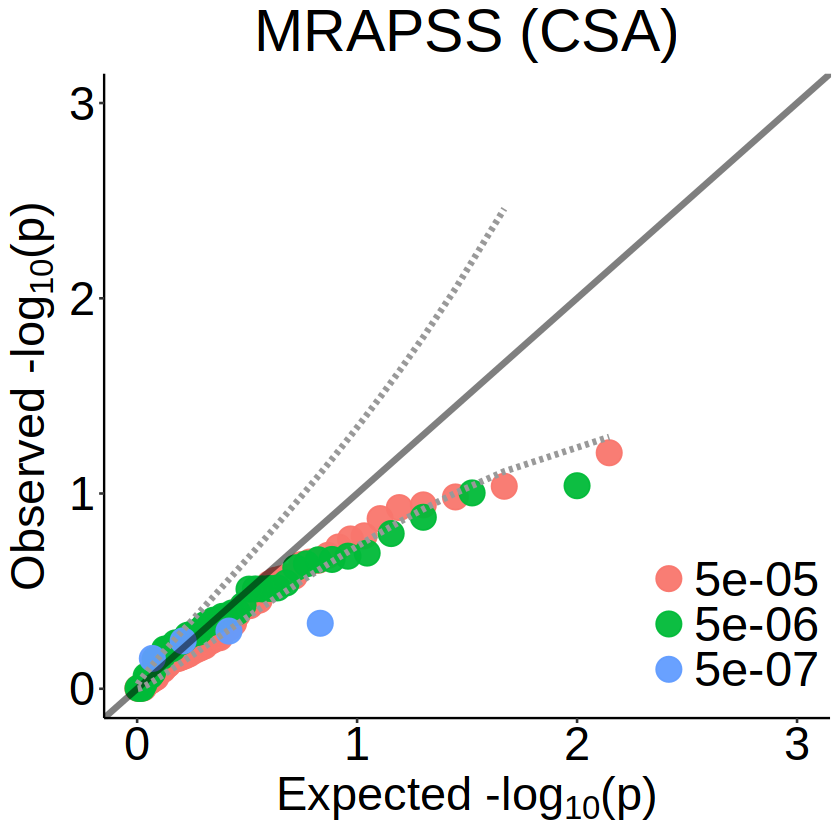

In [35]:
res_mrapss_CSA = fread("./CSA_results/MRAPSS.MRres")
res_mrapss_CSA = as.data.frame(res_mrapss_CSA)
colnames(res_mrapss_CSA) = c('exposure','outcome','beta','beta.se','beta.pvalue','tau.sq','nIV','pi0','IVsignal.sum','Threshold')
res_mrapss_CSA = res_mrapss_CSA[as.numeric(res_mrapss_CSA$nIV) > 3, ]

res_mrapss_CSA$beta.pvalue = as.numeric(res_mrapss_CSA$beta.pvalue)
qqplot_unequal_len(as.data.table(distinct(res_mrapss_CSA)), method_col = 'Threshold', pval_col = 'beta.pvalue', 
                   title = "MRAPSS (CSA)", max=3, xlim=3,  size=6.5)

ggsave(paste0(base_dir, "/plots/MRAPSS_CSA.png"), width = 7, height = 6, bg = 'white')

### TEMR

Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”


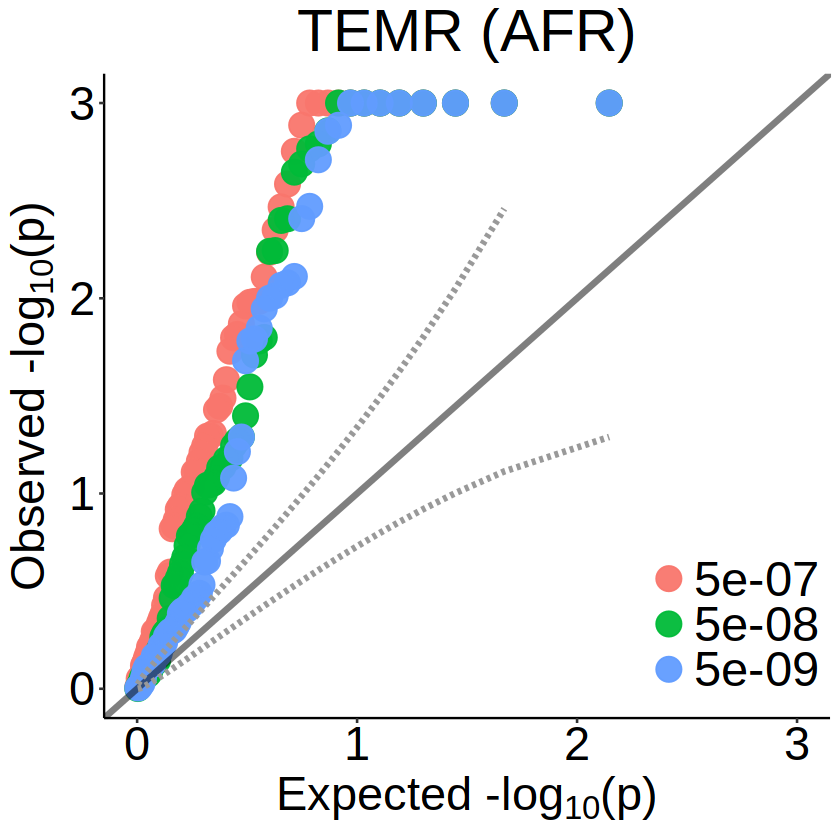

In [31]:
res_temr_AFR = fread("./AFR_results/TEMR.MRres")
res_temr_AFR = as.data.frame(res_temr_AFR)
colnames(res_temr_AFR) = c("exposure", "outcome", "beta", "beta.pvalue", "stat", "nIV", "Threshold")
res_temr_AFR = res_temr_AFR[as.numeric(res_temr_AFR$nIV) > 3, ]

res_temr_AFR$beta.pvalue = as.numeric(res_temr_AFR$beta.pvalue)
qqplot_unequal_len(as.data.table(distinct(res_temr_AFR)), method_col = 'Threshold', pval_col = 'beta.pvalue', 
                   color_thresh='789', title = "TEMR (AFR)", max=3, xlim=3,  size=6.5)

ggsave(paste0(base_dir, "/plots/TEMR_AFR.png"), width = 7, height = 6, bg = 'white')

Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”


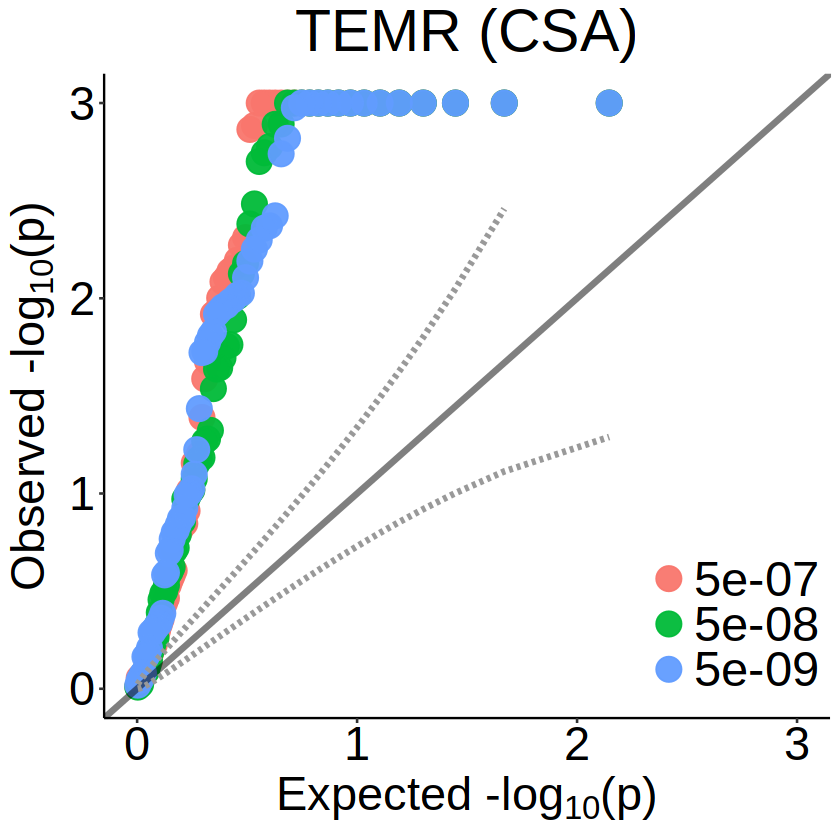

In [32]:
res_temr_CSA = fread("./CSA_results/TEMR.MRres")
res_temr_CSA = as.data.frame(res_temr_CSA)
colnames(res_temr_CSA) = c("exposure", "outcome", "beta", "beta.pvalue", "stat", "nIV", "Threshold")
res_temr_CSA = res_temr_CSA[as.numeric(res_temr_CSA$nIV) > 3, ]

res_temr_CSA$beta.pvalue = as.numeric(res_temr_CSA$beta.pvalue)
qqplot_unequal_len(as.data.table(distinct(res_temr_CSA)), method_col = 'Threshold', pval_col = 'beta.pvalue', 
                   color_thresh='789', title = "TEMR (CSA)", max=3, xlim=3,  size=6.5)

ggsave(paste0(base_dir, "/plots/TEMR_CSA.png"), width = 7, height = 6, bg = 'white')

### Two Sample MR (IVW, Egger, Weighted-mode, Weighted-median)

Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”


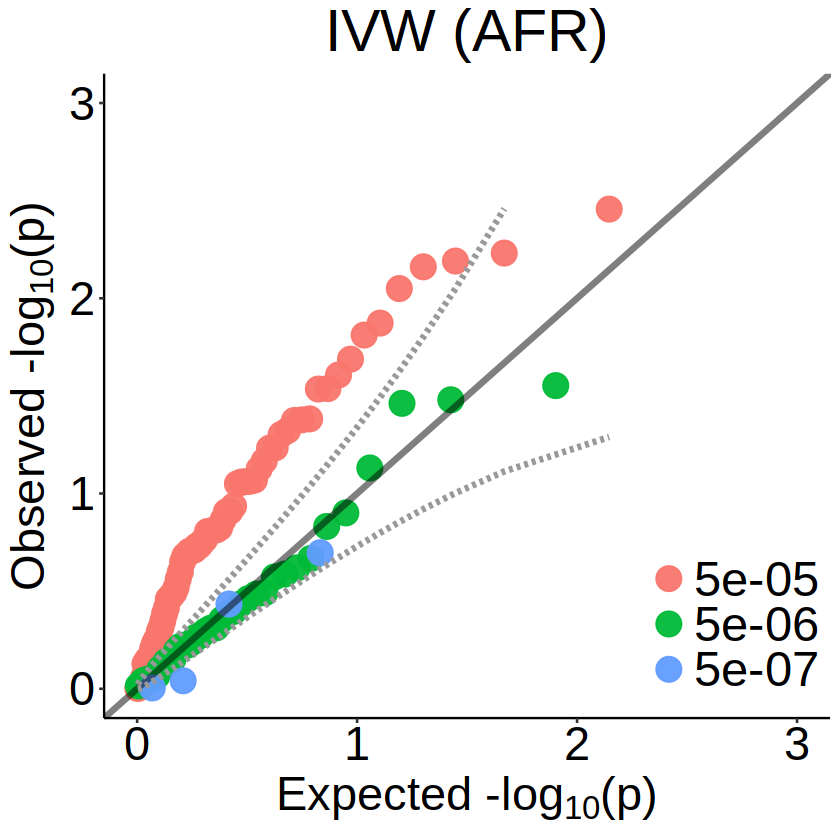

Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”


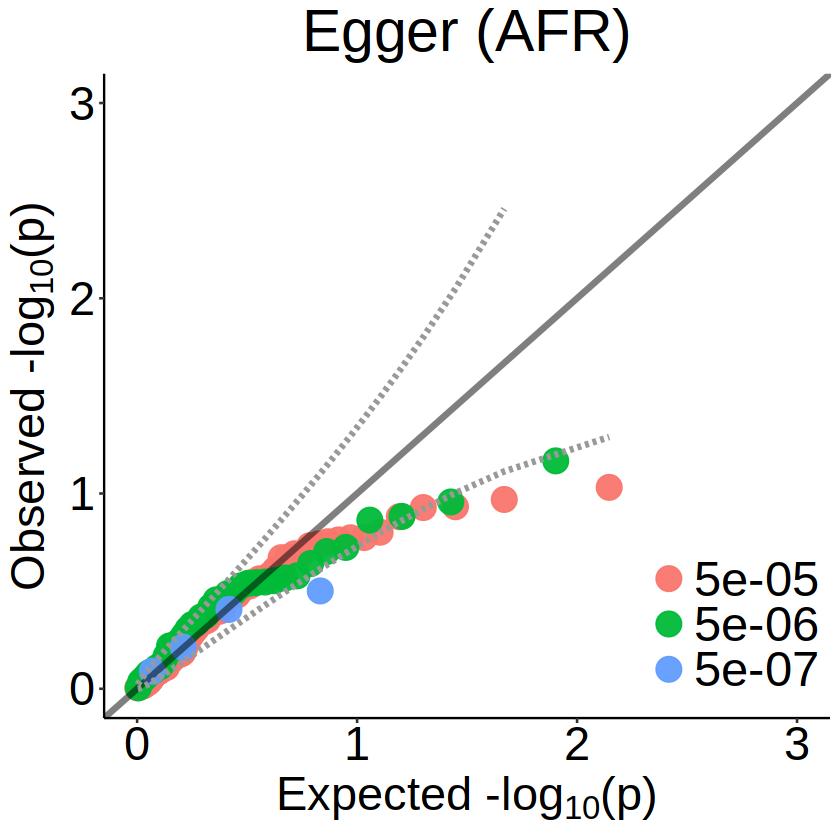

Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”


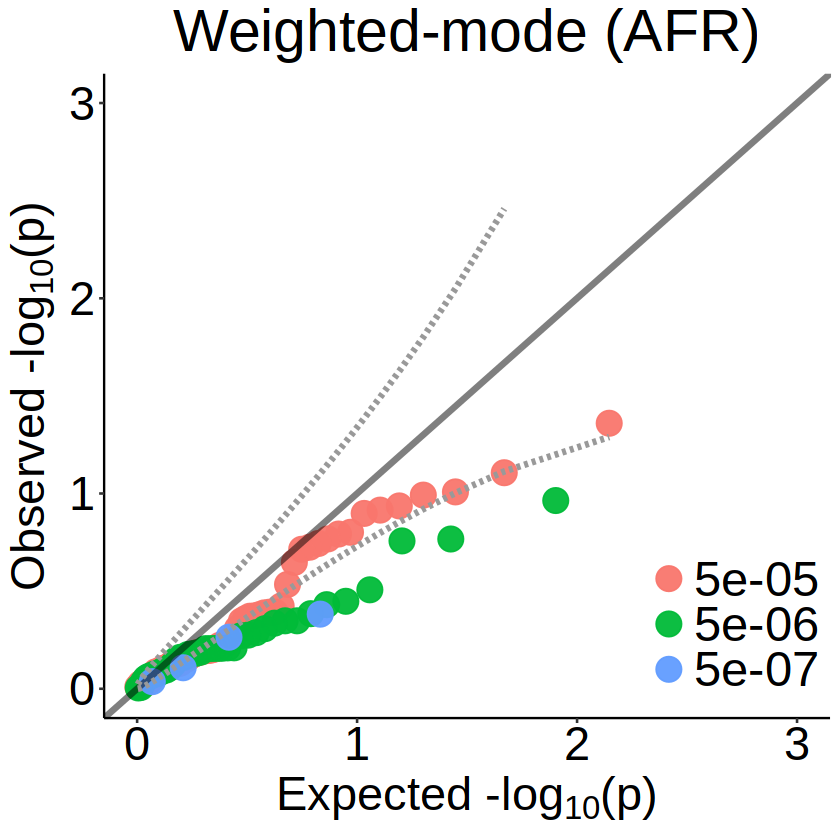

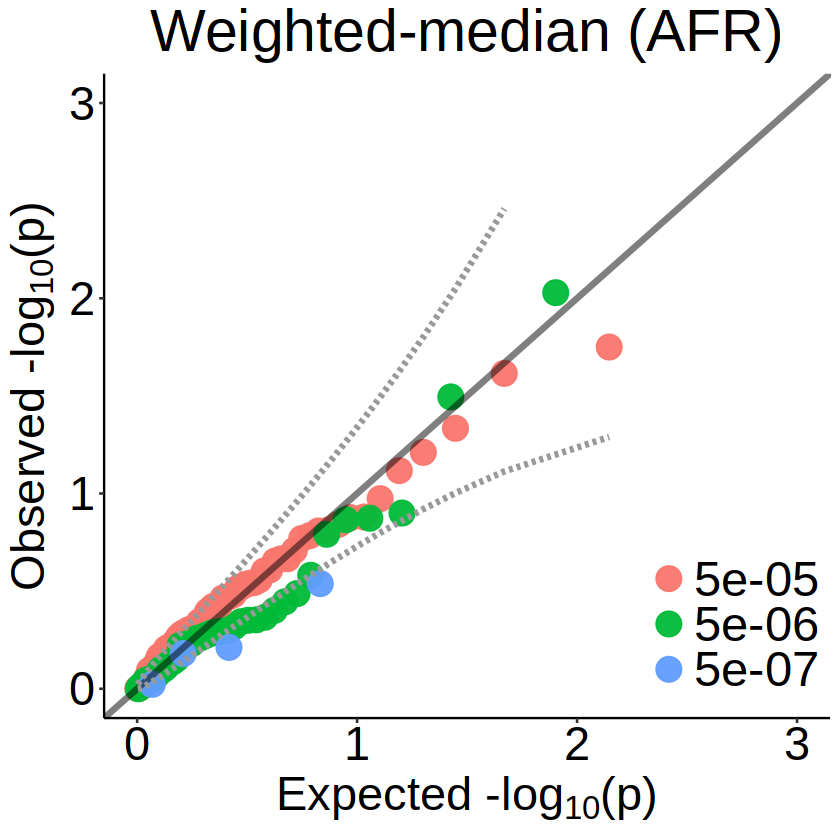

In [42]:
filename = c('IVW', 'Egger', 'Weightmode', 'Weightmed')
method = c('IVW', 'Egger', 'Weighted-mode', 'Weighted-median')

for(i in 1:4){
    res_AFR = fread(paste0("./AFR_results/",filename[i],".MRres"))
    res_AFR = as.data.frame(res_AFR)
    colnames(res_AFR) = c('exposure','outcome','beta','beta.se','beta.pvalue','nIV','Threshold')
    res_AFR = res_AFR[as.numeric(res_AFR$nIV) > 3, ]

    res_AFR$beta.pvalue = as.numeric(res_AFR$beta.pvalue)
    plot = qqplot_unequal_len(as.data.table(distinct(res_AFR)), method_col = 'Threshold', pval_col = 'beta.pvalue', 
                       title = paste0(method[i], " (AFR)"), max=3, xlim=3,  size=6.5)
    print(plot)
    ggsave(paste0(base_dir, "/plots/",method[i],"_AFR.png"), width = 7, height = 6, bg = 'white')
    
}

Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”


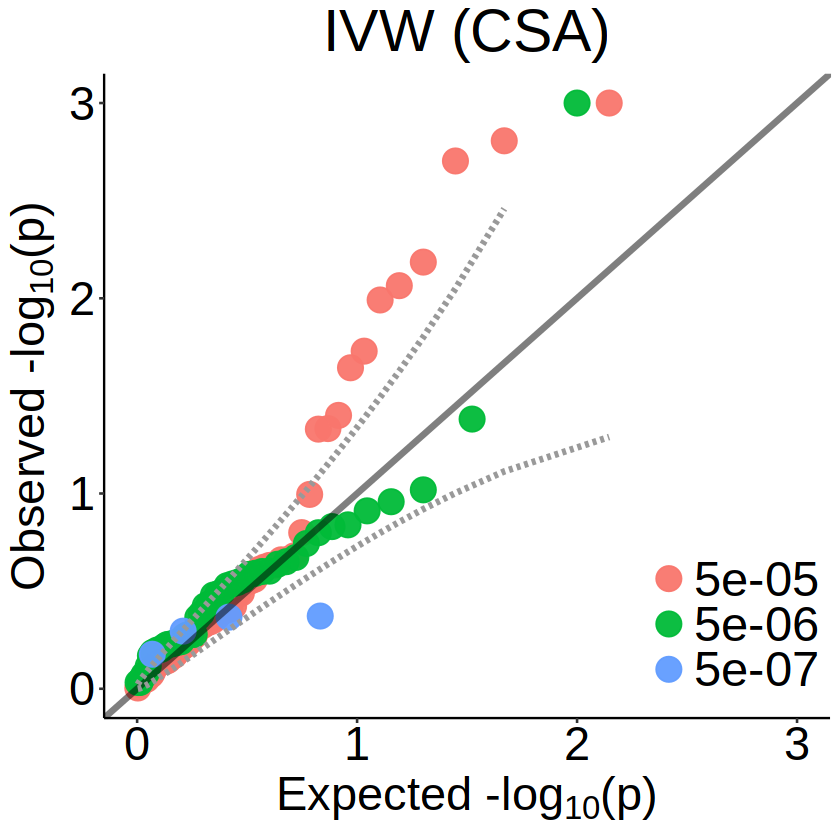

Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”


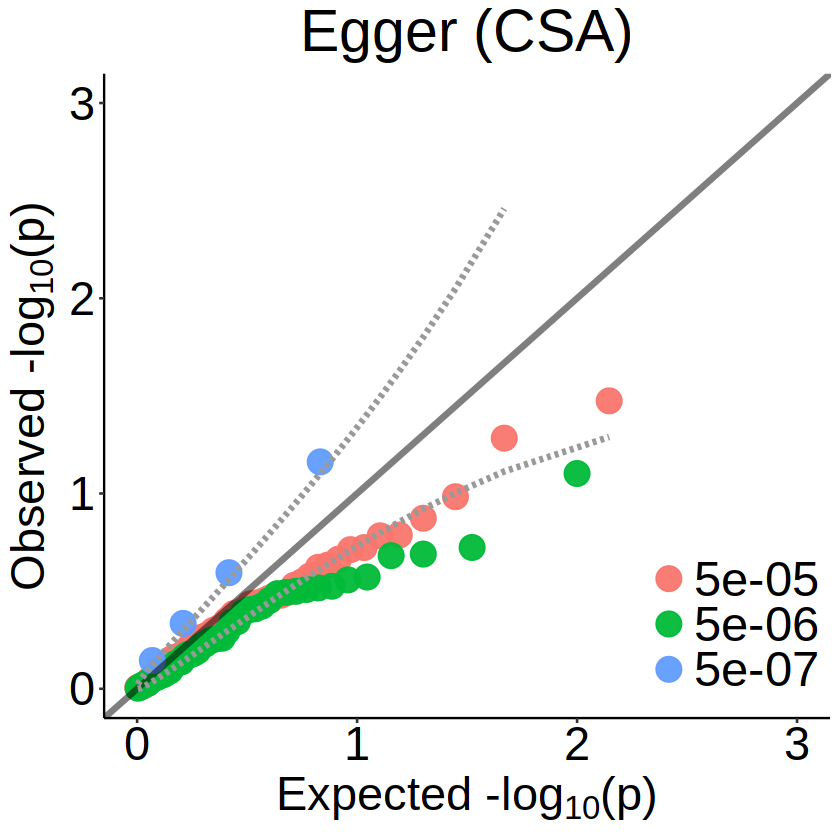

Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”


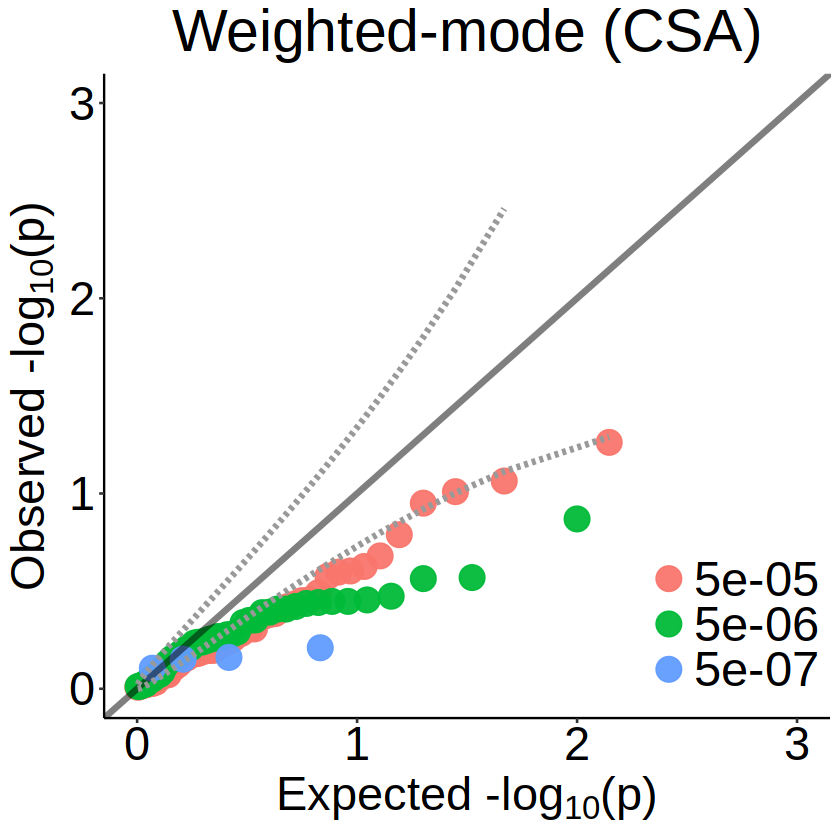

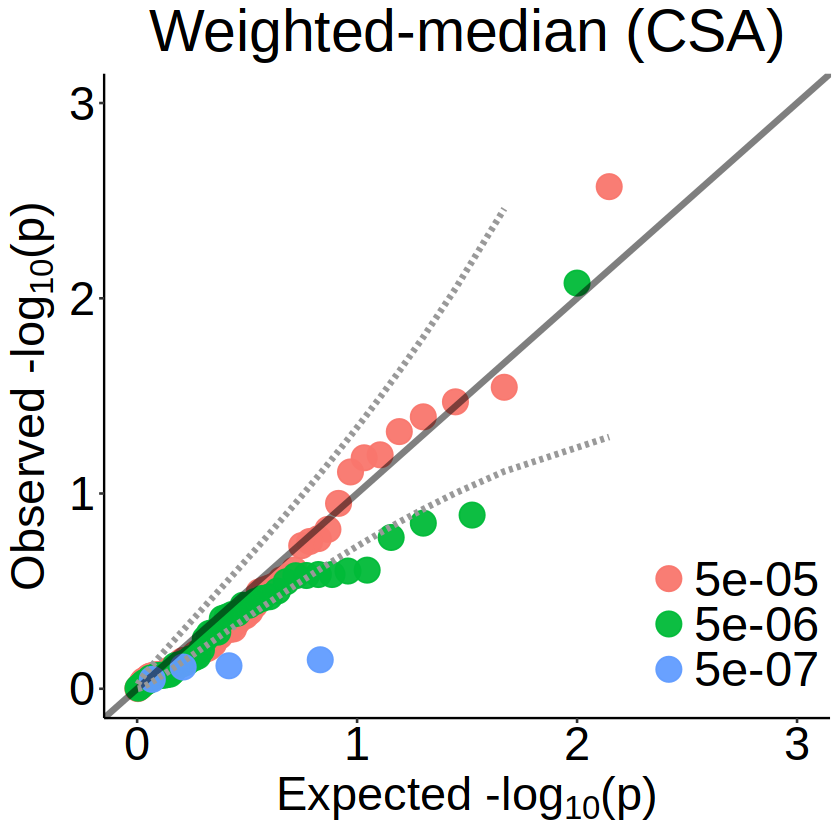

In [43]:
filename = c('IVW', 'Egger', 'Weightmode', 'Weightmed')
method = c('IVW', 'Egger', 'Weighted-mode', 'Weighted-median')

for(i in 1:4){
    res_CSA = fread(paste0("./CSA_results/",filename[i],".MRres"))
    res_CSA = as.data.frame(res_CSA)
    colnames(res_CSA) = c('exposure','outcome','beta','beta.se','beta.pvalue','nIV','Threshold')
    res_CSA = res_CSA[as.numeric(res_CSA$nIV) > 3, ]

    res_CSA$beta.pvalue = as.numeric(res_CSA$beta.pvalue)
    plot = qqplot_unequal_len(as.data.table(distinct(res_CSA)), method_col = 'Threshold', pval_col = 'beta.pvalue', 
                       title = paste0(method[i], " (CSA)"), max=3, xlim=3,  size=6.5)
    print(plot)
    ggsave(paste0(base_dir, "/plots/",method[i],"_CSA.png"), width = 7, height = 6, bg = 'white')
    
}

### IVW_fe, MRMix, MR-Robust, MR-Lasso, cML-MA, MR-PRESSO

Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”


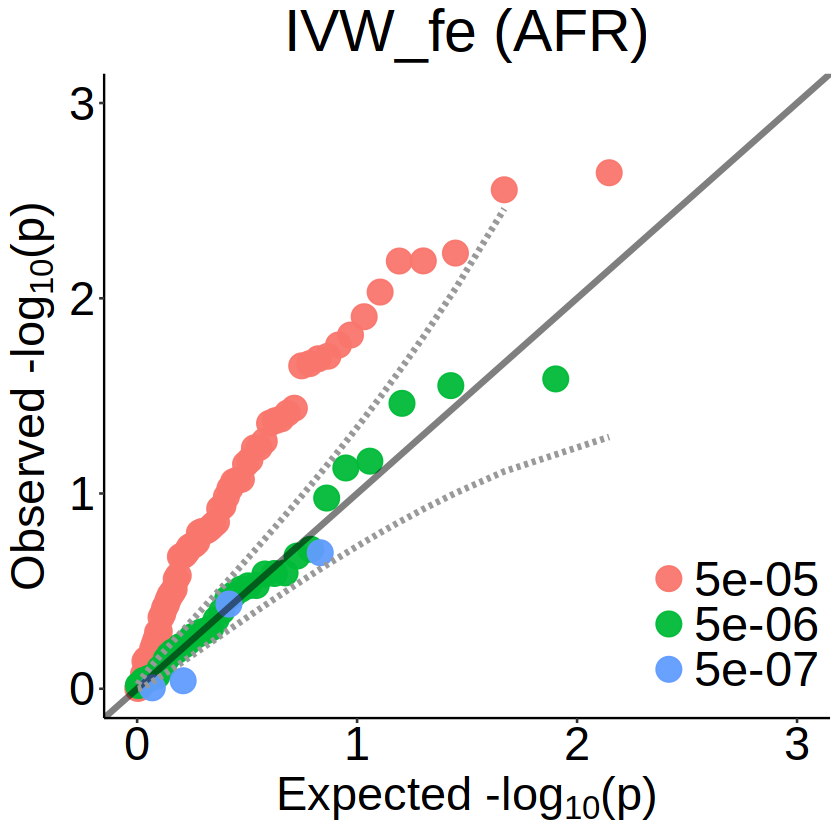

Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”


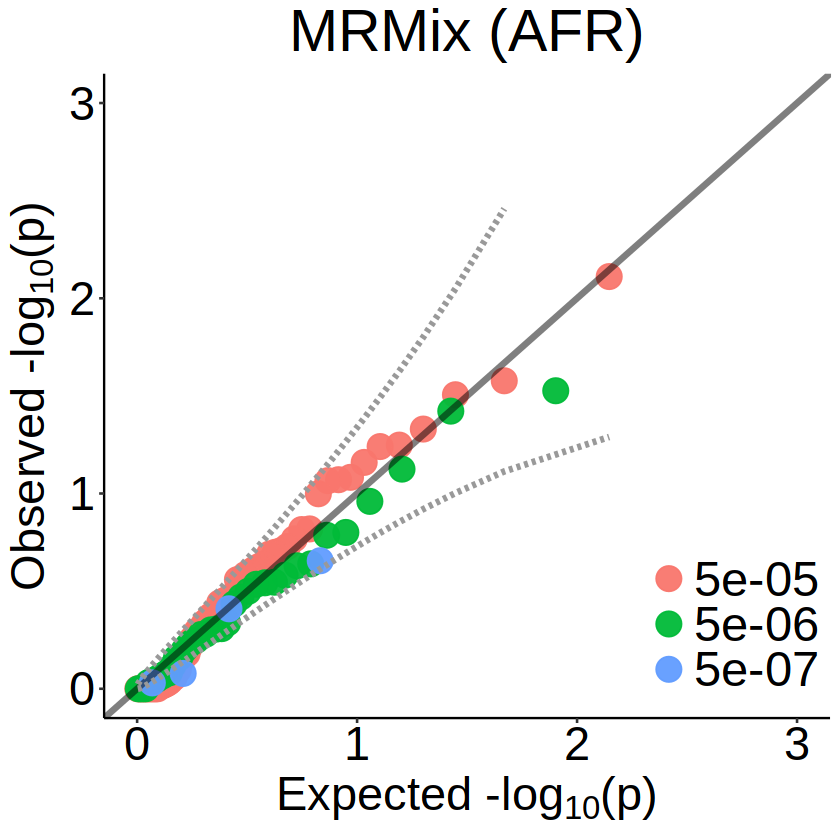

Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”


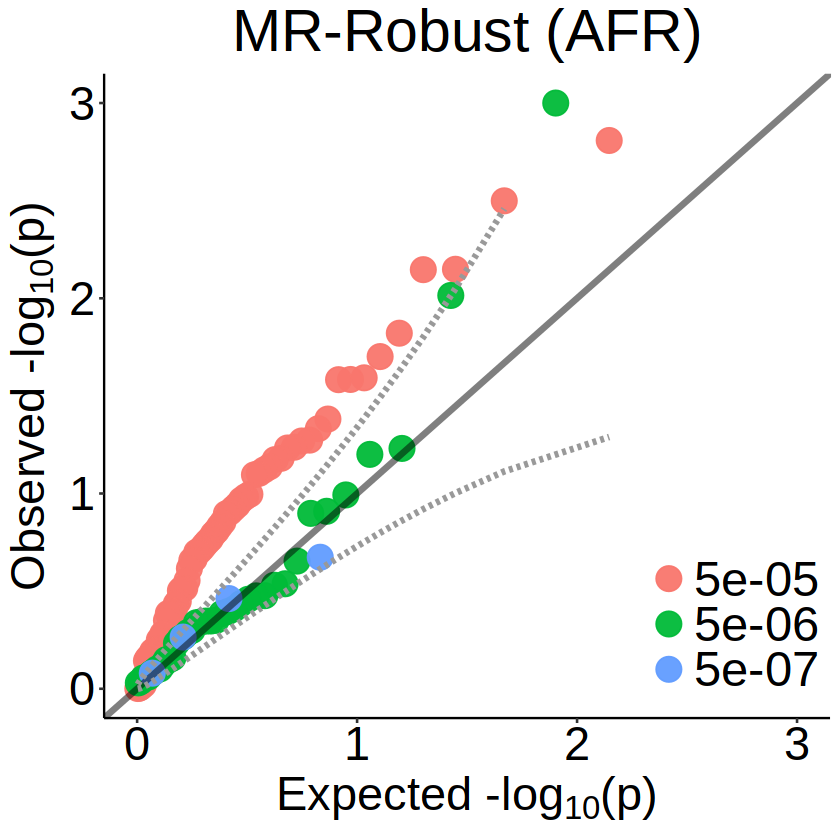

Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”


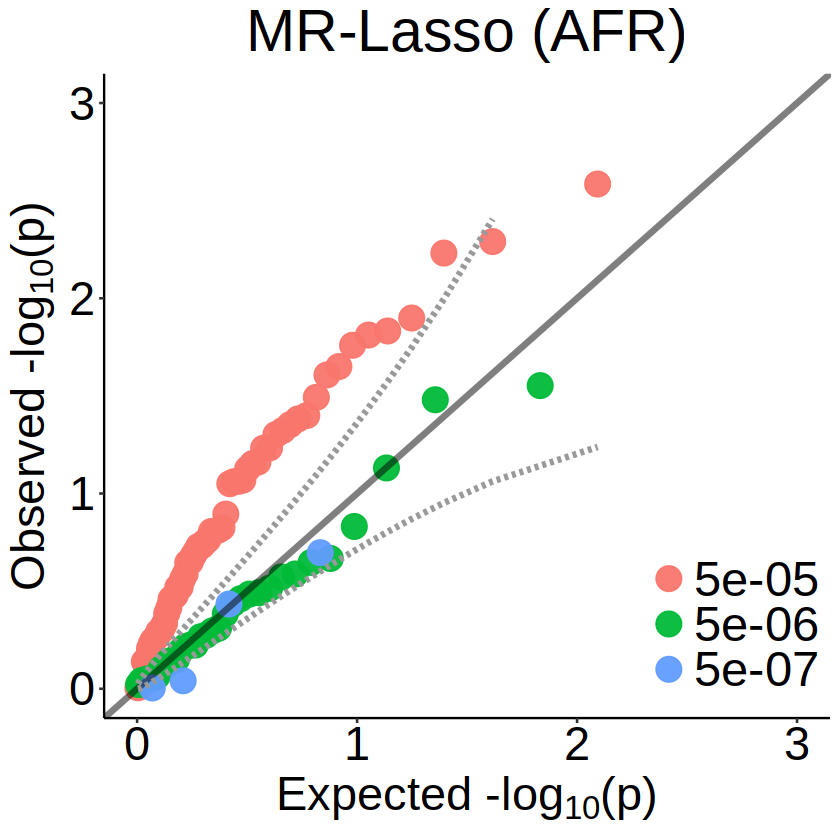

Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”


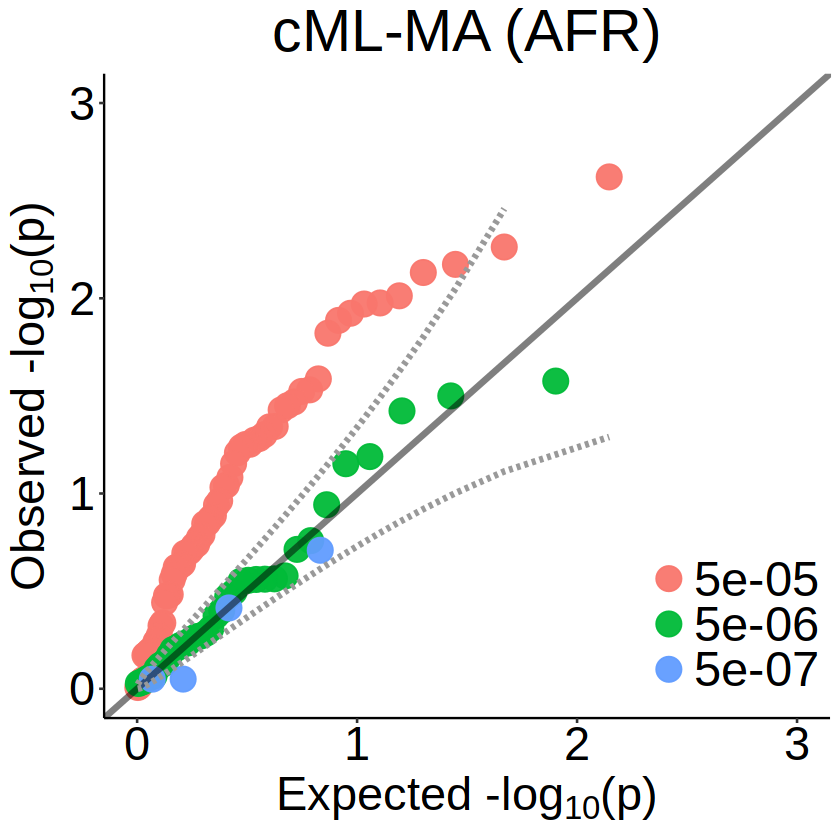

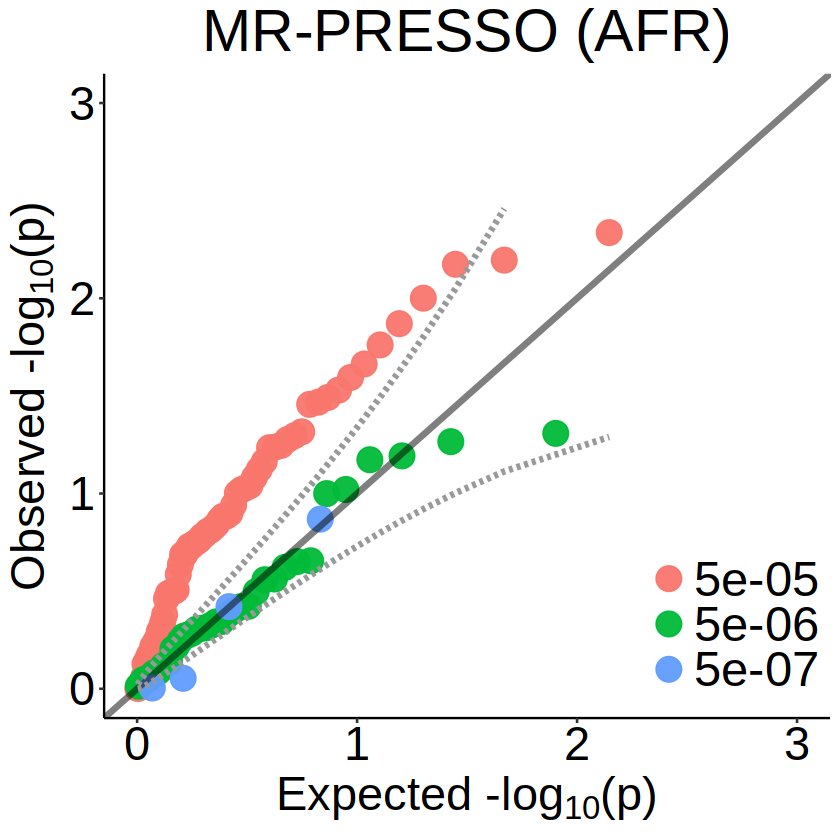

In [49]:
for(i in c("IVW_fe", "MRMix", "MR-Robust", "MR-Lasso", "cML-MA", "MR-PRESSO")){
    
    res_AFR = fread(paste0("./AFR_results/",i,".MRres"))
    res_AFR = as.data.frame(res_AFR)
    colnames(res_AFR) = c('exposure','outcome','method','Threshold','nIV','beta','beta.se','beta.pvalue')
    res_AFR = res_AFR[as.numeric(res_AFR$nIV) > 3, ]

    res_AFR$beta.pvalue = as.numeric(res_AFR$beta.pvalue)
    plot = qqplot_unequal_len(as.data.table(distinct(res_AFR)), method_col = 'Threshold', pval_col = 'beta.pvalue', 
                       title = paste0(i, " (AFR)"), max=3, xlim=3,  size=6.5)
    print(plot)
    ggsave(paste0(base_dir, "/plots/",i,"_AFR.png"), width = 7, height = 6, bg = 'white')
    
}

Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”


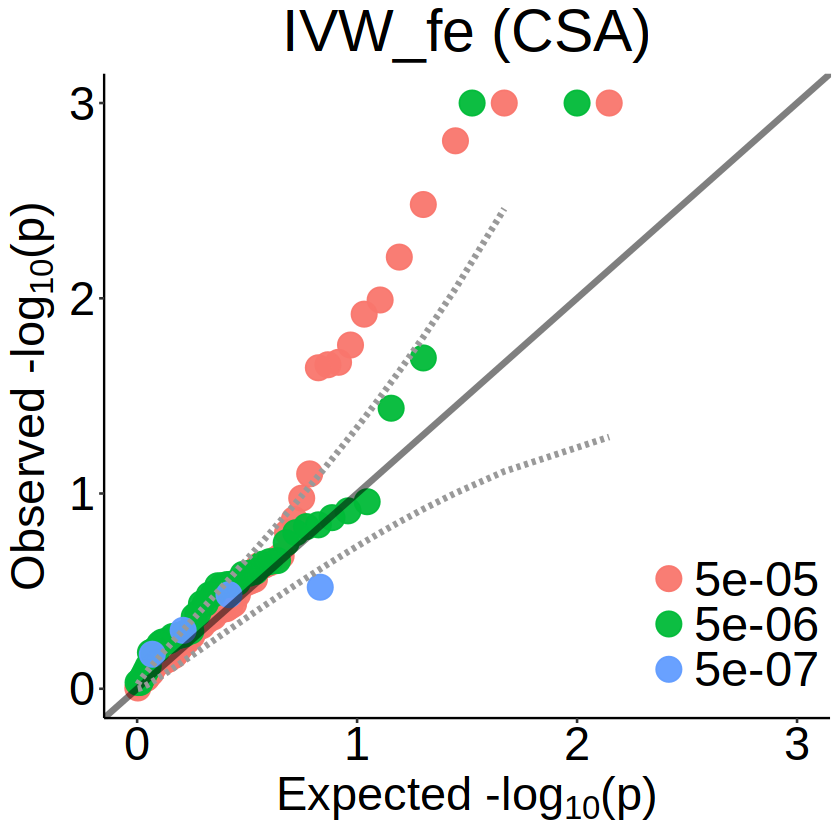

Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”


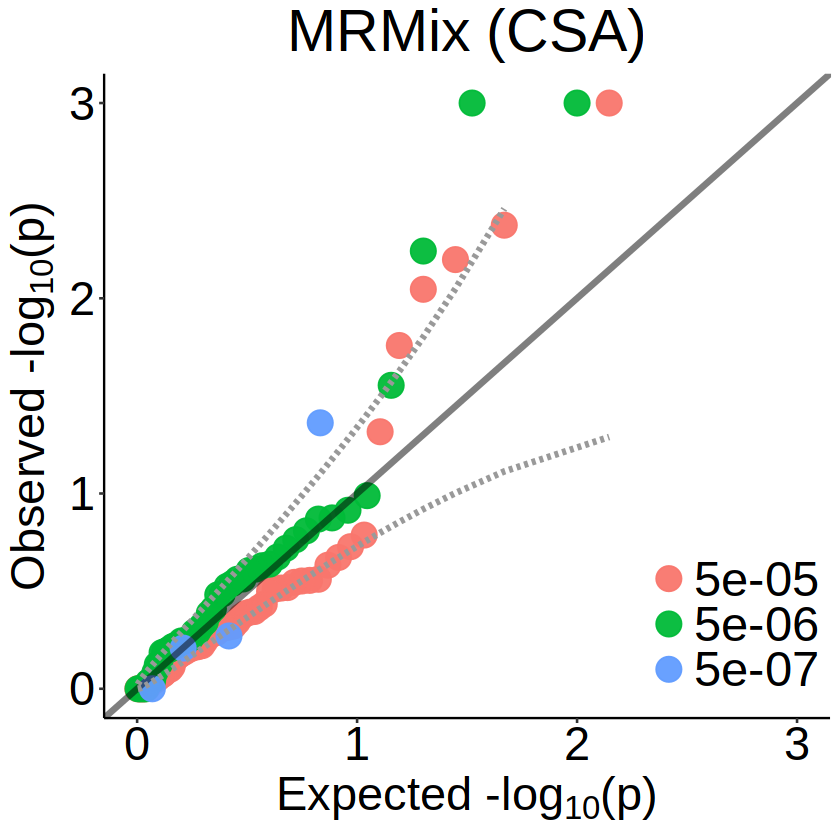

Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”


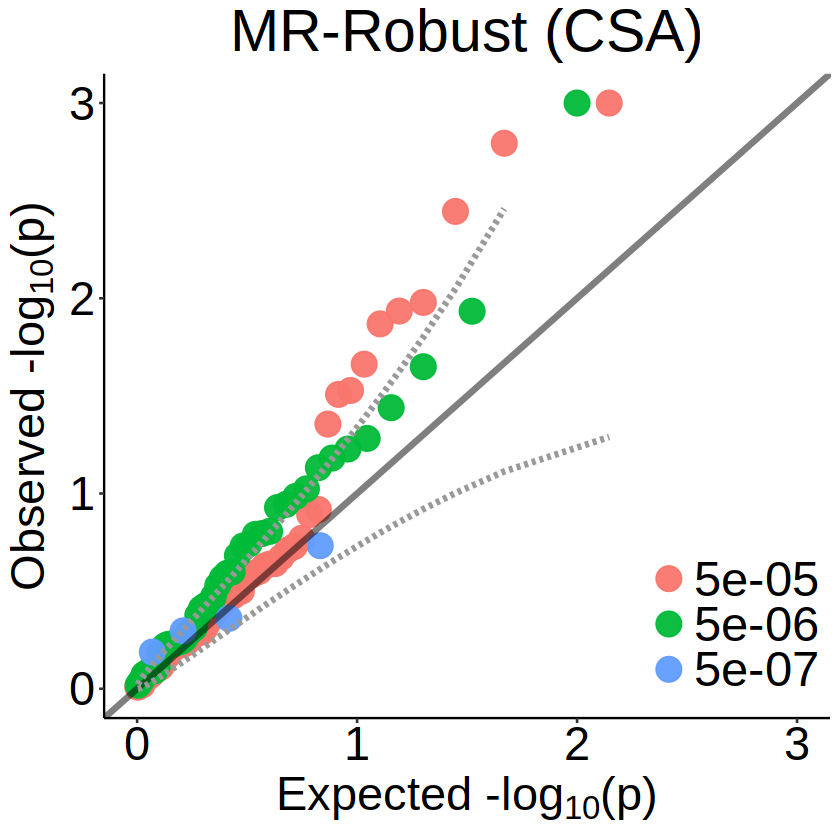

Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”


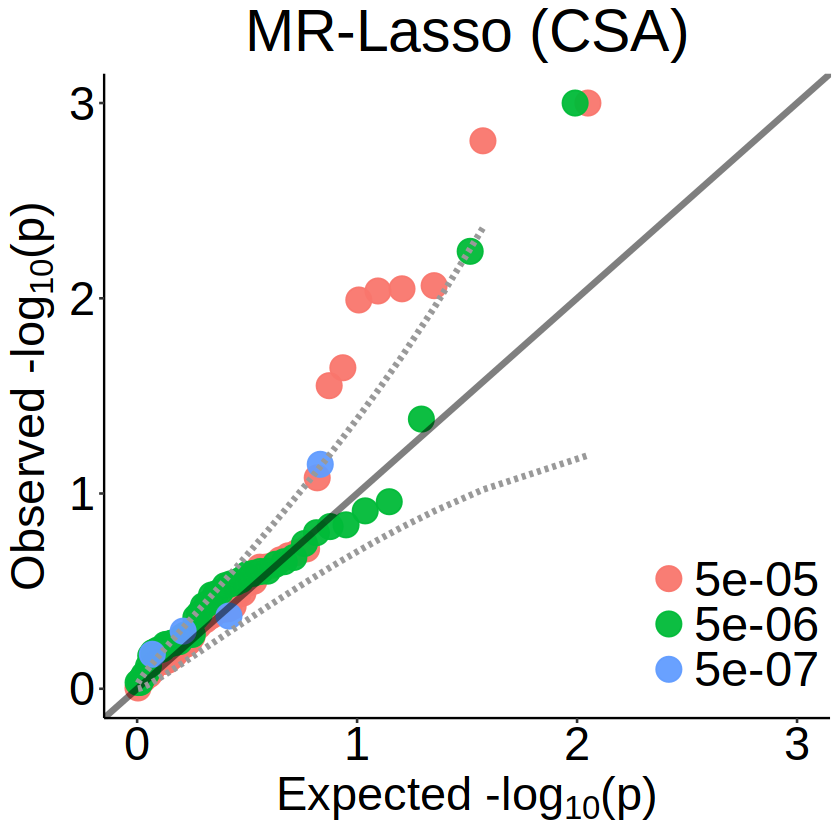

Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”


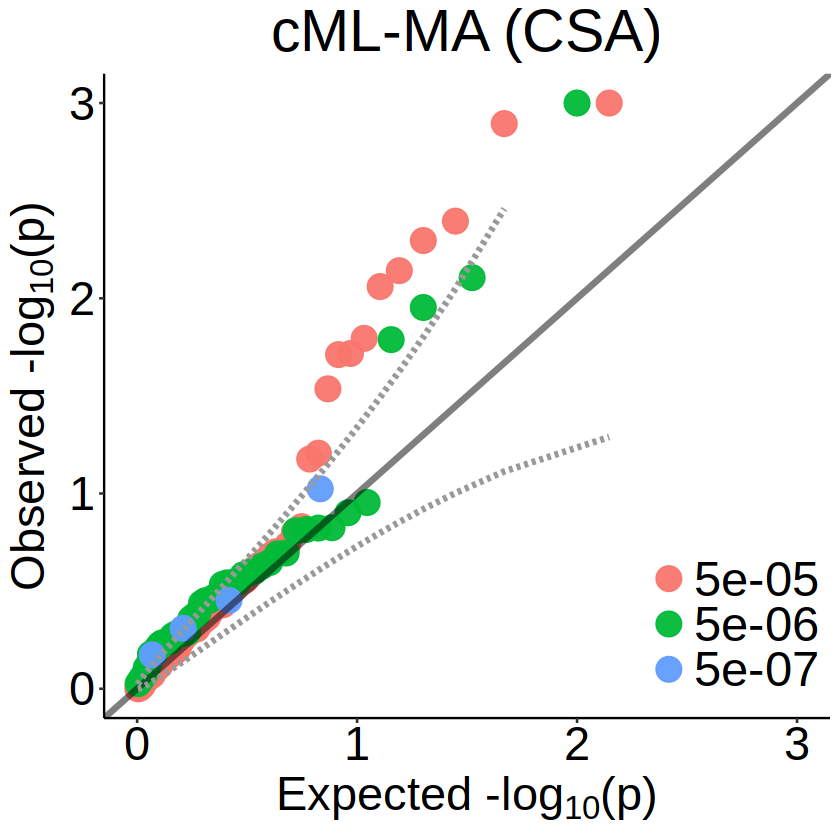

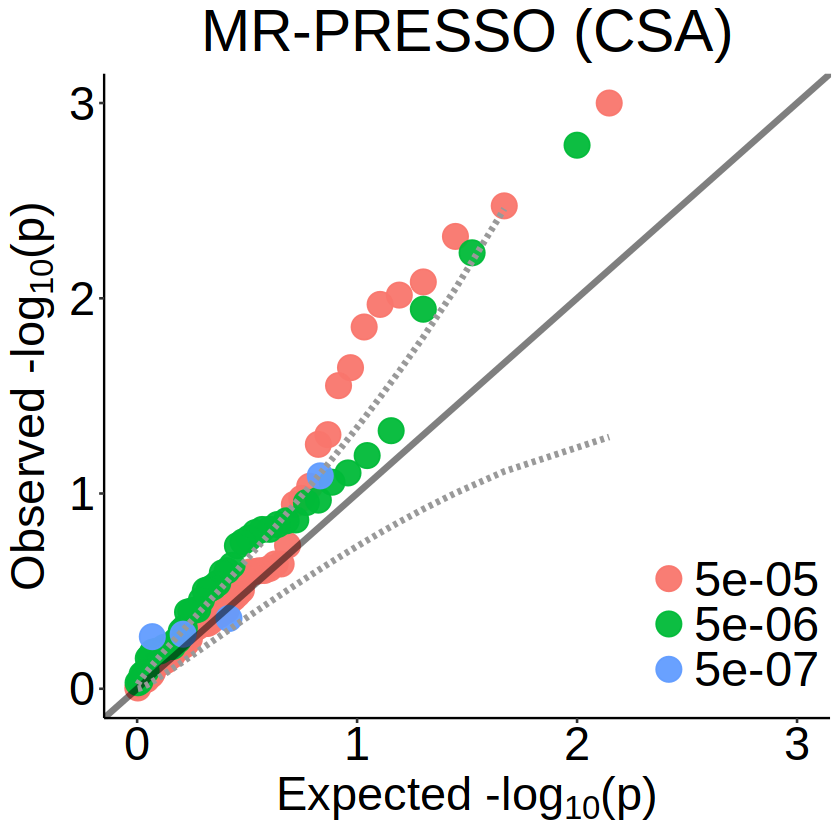

In [50]:
for(i in c("IVW_fe", "MRMix", "MR-Robust", "MR-Lasso", "cML-MA", "MR-PRESSO")){
    
    res_CSA = fread(paste0("./CSA_results/",i,".MRres"))
    res_CSA = as.data.frame(res_CSA)
    colnames(res_CSA) = c('exposure','outcome','method','Threshold','nIV','beta','beta.se','beta.pvalue')
    res_CSA = res_CSA[as.numeric(res_CSA$nIV) > 3, ]

    res_CSA$beta.pvalue = as.numeric(res_CSA$beta.pvalue)
    plot = qqplot_unequal_len(as.data.table(distinct(res_CSA)), method_col = 'Threshold', pval_col = 'beta.pvalue', 
                       title = paste0(i, " (CSA)"), max=3, xlim=3,  size=6.5)
    print(plot)
    ggsave(paste0(base_dir, "/plots/",i,"_CSA.png"), width = 7, height = 6, bg = 'white')
    
}

### CAUSE

Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”


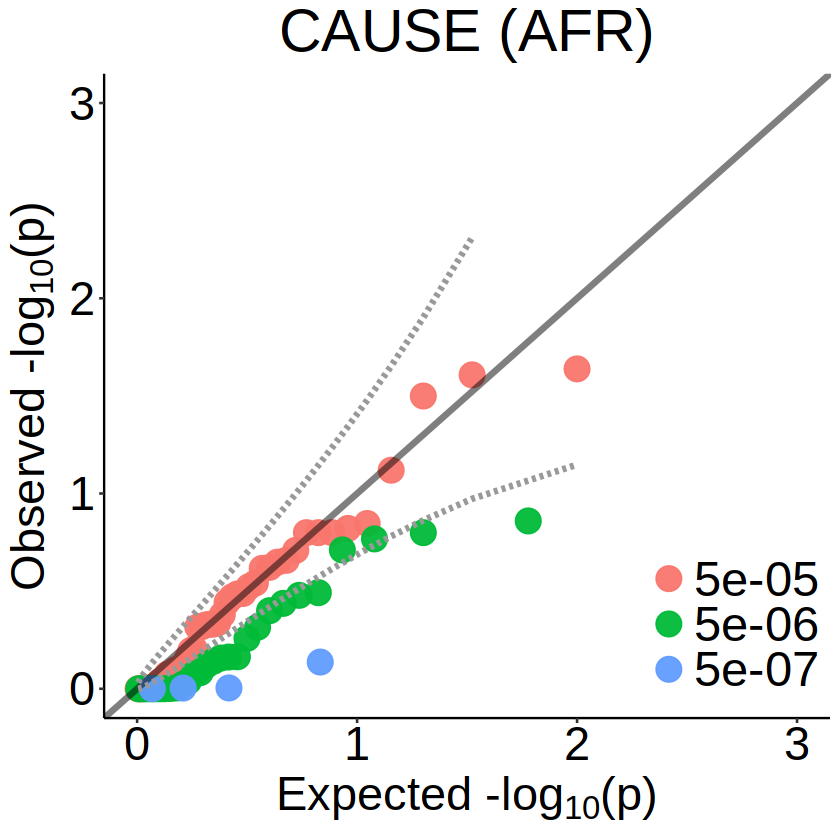

In [78]:
res_AFR = fread("./AFR_results/CAUSE.MRres")
res_AFR = as.data.frame(res_AFR)
colnames(res_AFR) = c('exposure', 'outcome', 'beta.pvalue', 'Threshold', 'nIV', 'beta', 'beta.se', 'method')
res_AFR = res_AFR[as.numeric(res_AFR$nIV) > 3, ]

res_AFR$beta.pvalue = as.numeric(res_AFR$beta.pvalue)
qqplot_unequal_len(as.data.table(na.omit(distinct(res_AFR))), method_col = 'Threshold', pval_col = 'beta.pvalue', 
                   title = "CAUSE (AFR)", max=3, xlim=3,  size=6.5)

ggsave(paste0(base_dir, "/plots/CAUSE_AFR.png"), width = 7, height = 6, bg = 'white')

Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”


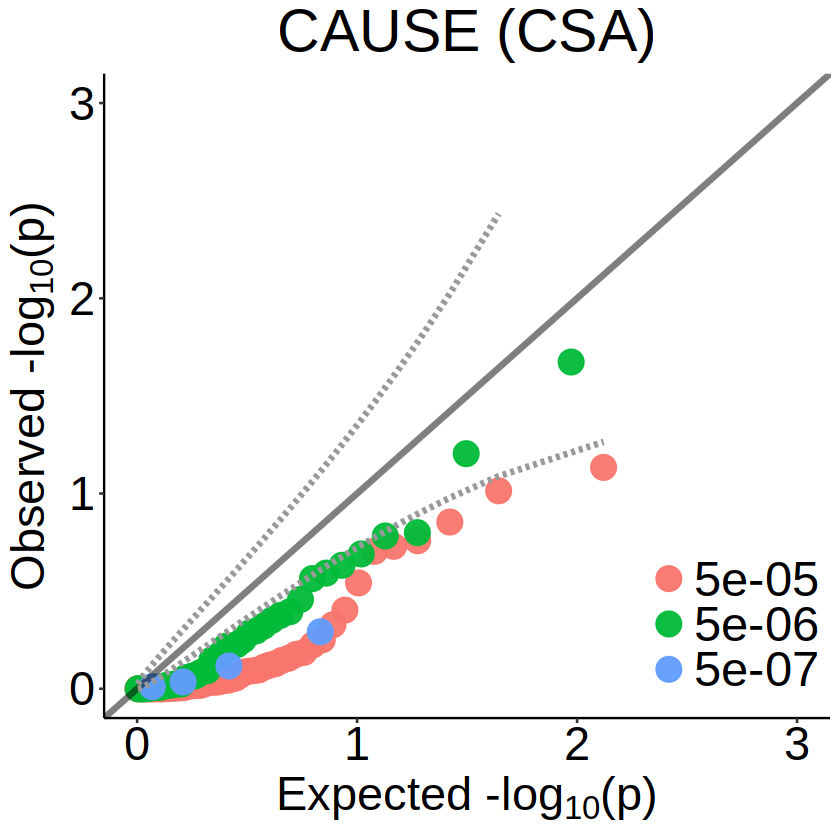

In [80]:
res_CSA = fread("./CSA_results/CAUSE.MRres")
res_CSA = as.data.frame(res_CSA)
colnames(res_CSA) = c('exposure', 'outcome', 'beta.pvalue', 'Threshold', 'nIV', 'beta', 'beta.se', 'method')
res_CSA = res_CSA[as.numeric(res_CSA$nIV) > 3, ]

res_CSA$beta.pvalue = as.numeric(res_CSA$beta.pvalue)
qqplot_unequal_len(as.data.table(na.omit(distinct(res_CSA))), method_col = 'Threshold', pval_col = 'beta.pvalue', 
                   title = "CAUSE (CSA)", max=3, xlim=3,  size=6.5)

ggsave(paste0(base_dir, "/plots/CAUSE_CSA.png"), width = 7, height = 6, bg = 'white')

### ConMix

Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”


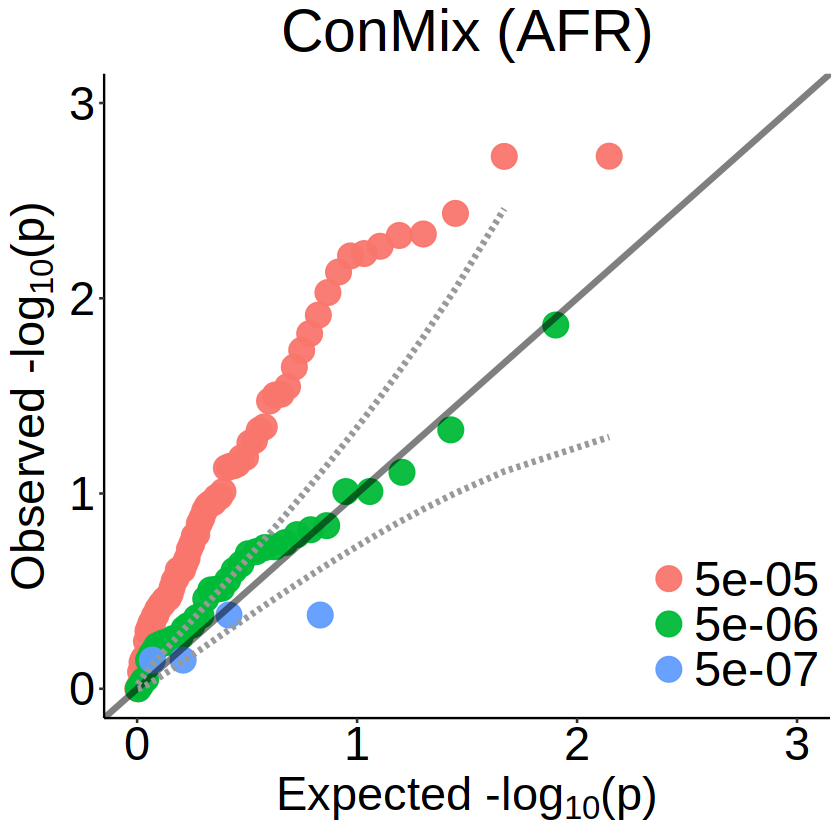

In [64]:
res_AFR = fread("./AFR_results/ConMix.MRres")
res_AFR = as.data.frame(res_AFR)
colnames(res_AFR) = c('exposure', 'outcome', 'method', 'Threshold', 'nIV', 'beta', 'beta.pvalue', 'CL', 'CU')
res_AFR = res_AFR[as.numeric(res_AFR$nIV) > 3, ]

res_AFR$beta.pvalue = as.numeric(res_AFR$beta.pvalue)
qqplot_unequal_len(as.data.table(distinct(res_AFR)), method_col = 'Threshold', pval_col = 'beta.pvalue', 
                   title = "ConMix (AFR)", max=3, xlim=3,  size=6.5)

ggsave(paste0(base_dir, "/plots/ConMix_AFR.png"), width = 7, height = 6, bg = 'white')

Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”


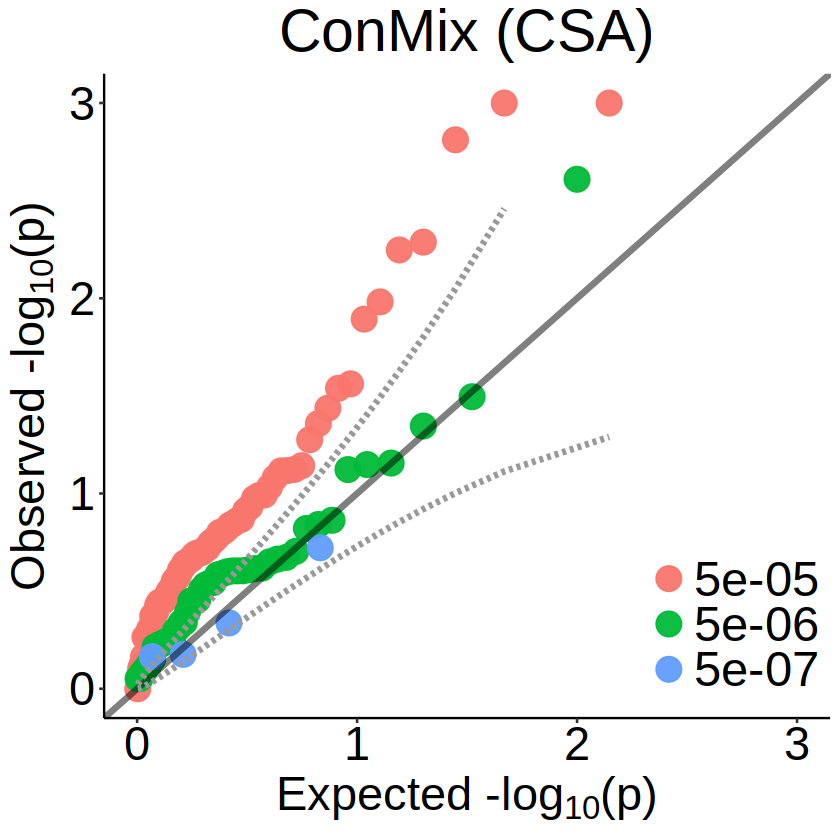

In [65]:
res_CSA = fread("./CSA_results/ConMix.MRres")
res_CSA = as.data.frame(res_CSA)
colnames(res_CSA) = c('exposure', 'outcome', 'method', 'Threshold', 'nIV', 'beta', 'beta.pvalue', 'CL', 'CU')
res_CSA = res_CSA[as.numeric(res_CSA$nIV) > 3, ]

res_CSA$beta.pvalue = as.numeric(res_CSA$beta.pvalue)
qqplot_unequal_len(as.data.table(distinct(res_CSA)), method_col = 'Threshold', pval_col = 'beta.pvalue', 
                   title = "ConMix (CSA)", max=3, xlim=3,  size=6.5)

ggsave(paste0(base_dir, "/plots/ConMix_CSA.png"), width = 7, height = 6, bg = 'white')

### dIVW

Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”


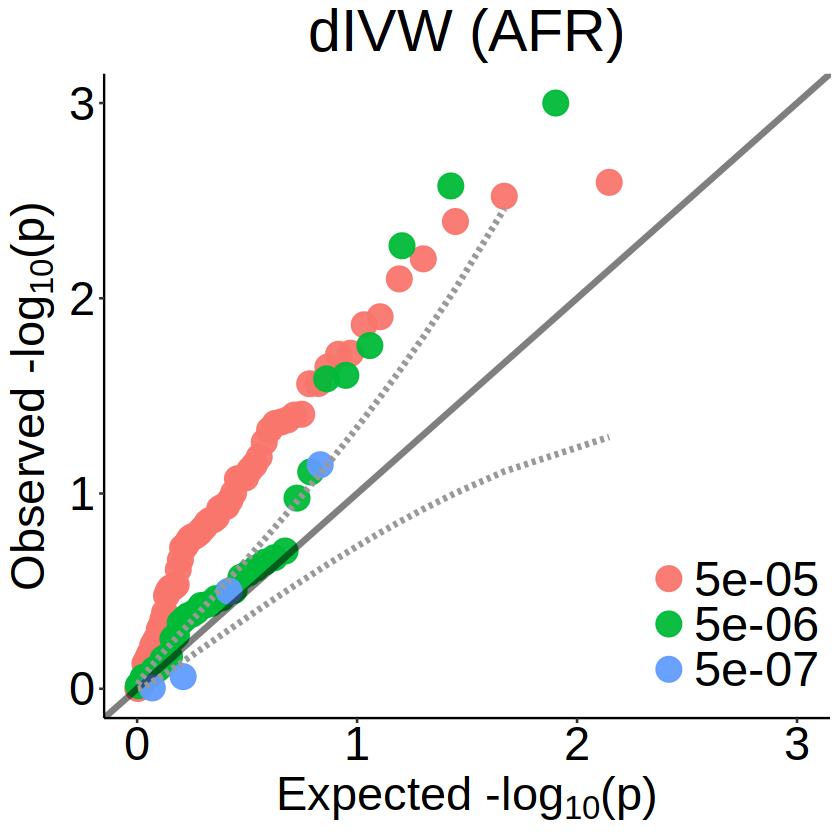

In [66]:
res_AFR = fread("./AFR_results/dIVW.MRres")
res_AFR = as.data.frame(res_AFR)
colnames(res_AFR) = c('exposure', 'outcome', 'method', 'Threshold', 'nIV', 'beta', 'beta.se', 'beta.pvalue')
res_AFR = res_AFR[as.numeric(res_AFR$nIV) > 3, ]

res_AFR$beta.pvalue = as.numeric(res_AFR$beta.pvalue)
qqplot_unequal_len(as.data.table(distinct(res_AFR)), method_col = 'Threshold', pval_col = 'beta.pvalue', 
                   title = "dIVW (AFR)", max=3, xlim=3,  size=6.5)

ggsave(paste0(base_dir, "/plots/dIVW_AFR.png"), width = 7, height = 6, bg = 'white')

Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_line()`).”


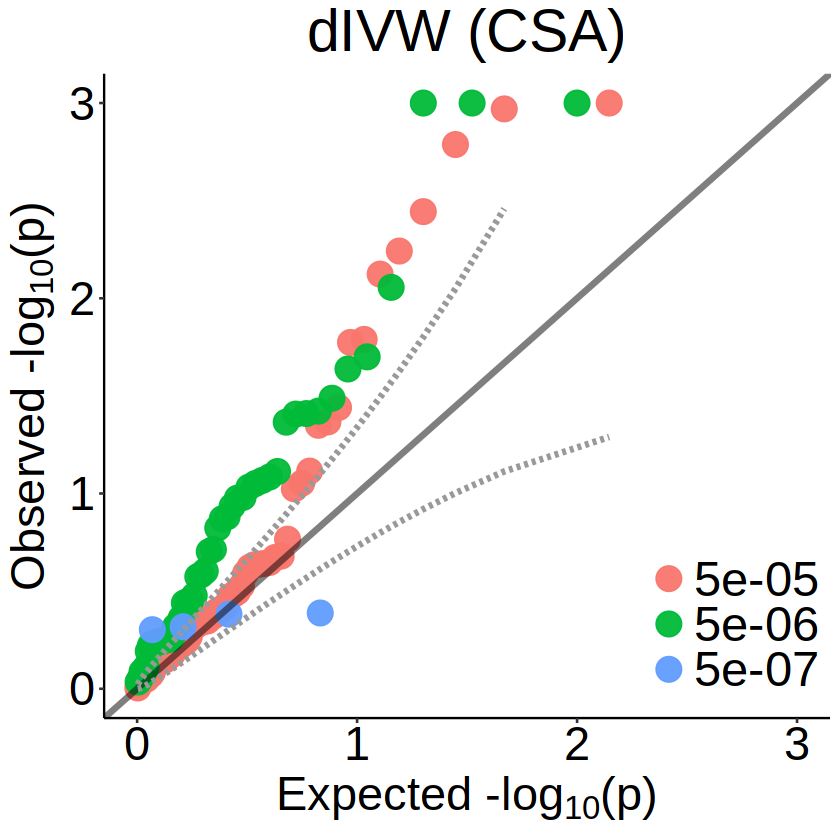

In [67]:
res_CSA = fread("./CSA_results/dIVW.MRres")
res_CSA = as.data.frame(res_CSA)
colnames(res_CSA) = c('exposure', 'outcome', 'method', 'Threshold', 'nIV', 'beta', 'beta.se', 'beta.pvalue')
res_CSA = res_CSA[as.numeric(res_CSA$nIV) > 3, ]

res_CSA$beta.pvalue = as.numeric(res_CSA$beta.pvalue)
qqplot_unequal_len(as.data.table(distinct(res_CSA)), method_col = 'Threshold', pval_col = 'beta.pvalue', 
                   title = "dIVW (CSA)", max=3, xlim=3,  size=6.5)

ggsave(paste0(base_dir, "/plots/dIVW_CSA.png"), width = 7, height = 6, bg = 'white')

### IV numbers of two-sample MR methods

Ignoring unknown labels:
• fill : "Threshold"
Ignoring unknown labels:
• fill : "Threshold"


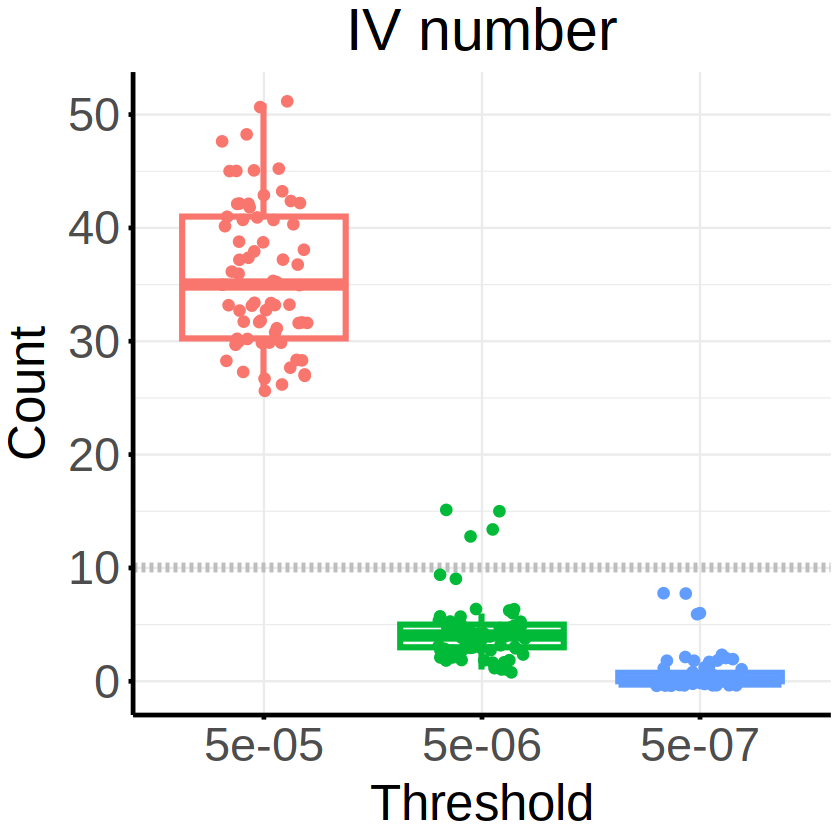

In [75]:
res_AFR = fread("./AFR_results/dIVW.MRres")
res_AFR = as.data.frame(res_AFR)
colnames(res_AFR) = c('exposure', 'outcome', 'method', 'Threshold', 'nIV', 'beta', 'beta.se', 'beta.pvalue')

divw5 = res_AFR[res_AFR$Threshold==5e-5,]
divw6 = res_AFR[res_AFR$Threshold==5e-6,]
divw7 = res_AFR[res_AFR$Threshold==5e-7,]

res_long = data.frame(method = c(rep('dIVW', 210)),
                      threshold = c(rep(c('5e-05', '5e-06', '5e-07'), each=70)),
                      nIV = c(c(divw5$nIV, rep(0, 70-dim(divw5)[1])),
                              c(divw6$nIV, rep(0, 70-dim(divw6)[1])),
                              c(divw7$nIV, rep(0, 70-dim(divw7)[1]))))


ggplot(res_long, aes(x = threshold, y = nIV, color = threshold)) +
    geom_boxplot(outlier.shape = NA, outlier.size = 2, size=1.3) +  # 添加箱线图，设置离群点样式
    geom_hline(aes(yintercept = 10), linetype = "dashed", color = "grey", size = 2.1) +
    geom_jitter(position = position_jitter(width = 0.2), size = 2.5, alpha = 1) +  # 添加抖动散点
    #scale_color_manual(values = c("red", "green", "blue")) +
    ylab("Count") +
    theme_minimal(base_size = 14) +  # 设置主题
    labs(title = "IV number",
         x = "Threshold",
         #y = "nIV",
         fill = "Threshold",
         color = "Threshold") +
    theme_minimal()+
  theme(
    plot.title = element_text(            
      size = 35,                          
      #face = "bold",                      
      hjust = 0.5                         
    ),
    axis.title.y = element_text(           
      size = 30,
      margin = margin(r = 8)
    ),
    axis.title.x = element_text(           
      size = 30,
      margin = margin(t = 8)
    ),
    axis.text = element_text(             
      size = 28                      
    ),
    axis.text.x = element_text(  
      size = 28,
      #angle = 20,
      hjust = 0.5                       
    ),  
    axis.text.y = element_text(           
      size = 28                         
    ),
    legend.position = "none",
    text = element_text(size = 28),
    #panel.grid = element_blank(),              # 去掉背景的格子线
    panel.background = element_blank(),        # 移除背景
    axis.line = element_line(size = 1, color = "black"),  # 启用 x 和 y 轴线
    axis.ticks = element_line(size = 1, color = "black")
  )

ggsave(paste0(base_dir, "/plots/IV_num_AFR.png"), width = 8, height = 6, bg='white')

Ignoring unknown labels:
• fill : "Threshold"
Ignoring unknown labels:
• fill : "Threshold"


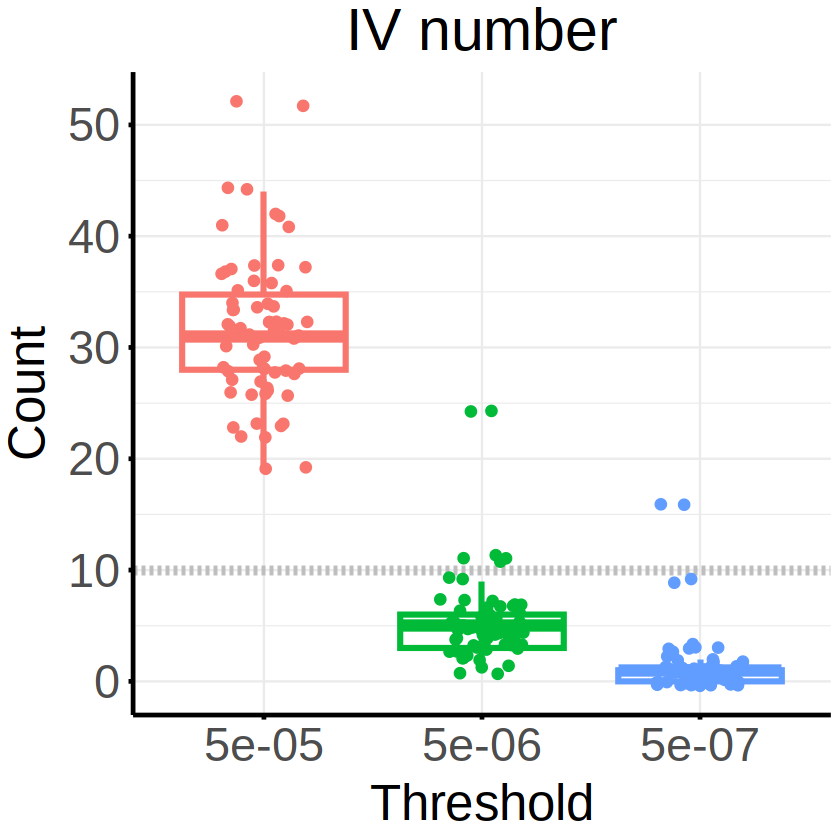

In [76]:
res_CSA = fread("./CSA_results/dIVW.MRres")
res_CSA = as.data.frame(res_CSA)
colnames(res_CSA) = c('exposure', 'outcome', 'method', 'Threshold', 'nIV', 'beta', 'beta.se', 'beta.pvalue')

divw5 = res_CSA[res_CSA$Threshold==5e-5,]
divw6 = res_CSA[res_CSA$Threshold==5e-6,]
divw7 = res_CSA[res_CSA$Threshold==5e-7,]

res_long = data.frame(method = c(rep('dIVW', 210)),
                      threshold = c(rep(c('5e-05', '5e-06', '5e-07'), each=70)),
                      nIV = c(c(divw5$nIV, rep(0, 70-dim(divw5)[1])),
                              c(divw6$nIV, rep(0, 70-dim(divw6)[1])),
                              c(divw7$nIV, rep(0, 70-dim(divw7)[1]))))


ggplot(res_long, aes(x = threshold, y = nIV, color = threshold)) +
    geom_boxplot(outlier.shape = NA, outlier.size = 2, size=1.3) +  # 添加箱线图，设置离群点样式
    geom_hline(aes(yintercept = 10), linetype = "dashed", color = "grey", size = 2.1) +
    geom_jitter(position = position_jitter(width = 0.2), size = 2.5, alpha = 1) +  # 添加抖动散点
    #scale_color_manual(values = c("red", "green", "blue")) +
    ylab("Count") +
    theme_minimal(base_size = 14) +  # 设置主题
    labs(title = "IV number",
         x = "Threshold",
         #y = "nIV",
         fill = "Threshold",
         color = "Threshold") +
    theme_minimal()+
  theme(
    plot.title = element_text(            
      size = 35,                          
      #face = "bold",                      
      hjust = 0.5                         
    ),
    axis.title.y = element_text(           
      size = 30,
      margin = margin(r = 8)
    ),
    axis.title.x = element_text(           
      size = 30,
      margin = margin(t = 8)
    ),
    axis.text = element_text(             
      size = 28                      
    ),
    axis.text.x = element_text(  
      size = 28,
      #angle = 20,
      hjust = 0.5                       
    ),  
    axis.text.y = element_text(           
      size = 28                         
    ),
    legend.position = "none",
    text = element_text(size = 28),
    #panel.grid = element_blank(),              # 去掉背景的格子线
    panel.background = element_blank(),        # 移除背景
    axis.line = element_line(size = 1, color = "black"),  # 启用 x 和 y 轴线
    axis.ticks = element_line(size = 1, color = "black")
  )

ggsave(paste0(base_dir, "/plots/IV_num_CSA.png"), width = 8, height = 6, bg='white')